# Analyse exploratoire du dataset reconstruit

## Exécution

Ce notebook utilise les fonctions partagées du dossier src. Les cellules s’exécutent dans l’ordre, sans accès aux sites du dataset. Les sorties détaillées et figures sont exportées dans reports. Aucun modèle ni découpage n’est produit.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
elif (BASE / "periode-1").is_dir():
    BASE = BASE / "periode-1"
assert (BASE / "src").is_dir(), "Ouvrir le notebook depuis le dépôt ou le dossier notebooks"
if str(BASE / "src") not in sys.path:
    sys.path.insert(0, str(BASE / "src"))
pd.set_option("display.max_columns", 22)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 40)


In [2]:
from analyse_data import run_analysis
outputs, summary = run_analysis()
print(summary)
FIG = BASE / "reports/figures/analyse_exploratoire"


{'rows': 235795, 'valid_rows': 235795, 'invalid_rows': 0, 'duplicate_url_excess': 425, 'duplicate_full_excess': 425, 'domain_groups_repeated': 5531, 'mixed_domains': 54, 'tld_count': 570, 'rare_tld_lt10': 300, 'feature_collision_groups_mixed': 292, 'near_constant_features': ['IsDomainIP_calc', 'has_percent_encoding', 'percent_encoded_count', 'percent_encoded_ratio'], 'constant_features': []}


# Analyse exploratoire du dataset reconstruit


## Périmètre et méthode

L'analyse porte sur le dataset reconstruit avant nettoyage : **235,795 lignes et 21 colonnes**, dont 18 caractéristiques. Toutes les statistiques utilisent les nouvelles conventions. Les anciens scores HTML ou externes n'interviennent plus. Les contrôles de validité rendent 235,795 lignes comparables et 0 lignes non comparables.

L'analyse est descriptive, non causale, et utilise l'ensemble du fichier. Elle ne mesure pas les performances d'un modèle. Un futur test issu du même fichier ne sera pas entièrement vierge d'exploration ; ses résultats ne devront pas servir à choisir les variables ou seuils après coup.


## Structure et valeurs manquantes

Il y a 17 entrées numériques, une entrée catégorielle, deux métadonnées et une cible binaire. Aucune caractéristique n'est manquante après extraction sur le fichier fourni. Le TLD vide des IP ou hôtes sans point est une modalité prévue. Il ne doit pas être transformé automatiquement en NaN.

L'identifiant FILENAME, les caractéristiques de page et les trois scores de référence ont été retirés des entrées. Les colonnes URL et Domain ne sont pas des entrées directes dans cette version ; elles servent aux vérifications et à une future séparation par groupes.


In [3]:
display(outputs["qualite"])

,type,manquantes,chaines_vides,valeurs_distinctes
variable,,,,
URL,str,0,0,235370
Domain,str,0,0,220077
label,int64,0,0,2
URLLength_calc,int64,0,0,481
DomainLength_calc,int64,0,0,101
IsDomainIP_calc,int64,0,0,2
IsHTTPS_calc,int64,0,0,2
TLDLength_calc,int64,0,0,13
NoOfLettersInURL_calc,int64,0,0,426


## Répartition des classes

| label | effectif | pourcentage |
| --- | --- | --- |
| 0 | 100945 | 42.810 |
| 1 | 134850 | 57.190 |


La majorité est légitime avec 57,19 % des lignes, contre 42,81 % de phishing. Le déséquilibre est modéré. Un système prédisant toujours légitime atteindrait 57,19 % d'accuracy sur ce fichier mais ne détecterait aucun phishing. Cette référence descriptive ne doit pas être présentée comme une performance de modèle entraîné.


,effectif,pourcentage
label,,
0,100945,42.810492
1,134850,57.189508


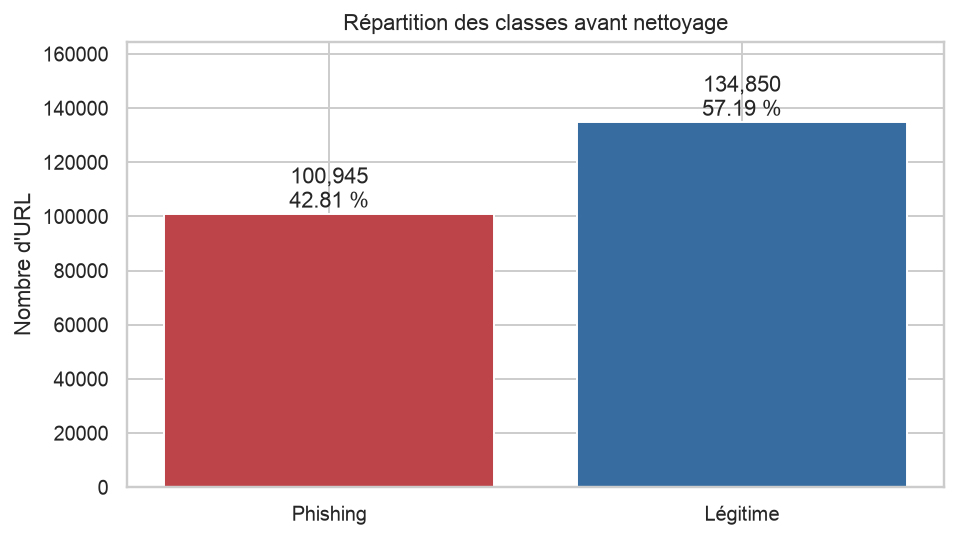

In [4]:
display(outputs["classes"])
display(Image(filename=str(FIG / "01_classes.png")))

## Doublons, domaines et collisions de caractéristiques

On observe 425 copies d'URL en excès et autant de lignes entièrement dupliquées. Elles proviennent de 425 URL présentes deux fois. Ces répétitions devront être supprimées avant le découpage. Il ne faut pas dédupliquer seulement les caractéristiques : deux URL différentes peuvent avoir les mêmes longueurs et compteurs.

Après extraction normalisée, 5531 hôtes sont répétés, dont 54 mixtes. Le nombre diffère de celui des champs Domain originaux parce que la définition de l'hôte change, notamment pour les ports et identifiants. Aucune égalité des domaines ne justifie à elle seule de supprimer les pages.

On compte 11,871 groupes de vecteurs répétés, couvrant 207,519 lignes. Parmi eux, **292 groupes réunissent les deux classes**. Une représentation par longueurs et compteurs perd de l'information : un même vecteur peut correspondre à des URL différentes et à des labels différents. Ces collisions ne sont pas des contradictions d'étiquette à URL identique et ne sont pas supprimées.


In [5]:
display(outputs["doublons_url"].head(10))
display(outputs["domaines"].head(10))
display(outputs["collisions_caracteristiques"])

,size,nunique
URL,,
http://2f3a.reicrut-chat.workers.dev/,2,1
http://34.149.138.117/,2,1
http://595221.selcdn.ru/qwerty-ohdhdjejnnad-najahhy/index4.html,2,1
http://595221.selcdn.ru/qwerty-ohdhdjejnnad-najahhy/index8.html,2,1
http://91.239.125.28/postchs/sms.php,2,1
http://akareal.com.vn/wp-admin/js/hku/sa/netfluinca/chun-g/account/sms2.php,2,1
http://app-batasotak1244acces.kvoiffugw9-yk26ed5vg379.p.temp-site.link/termsofservice.html,2,1
http://app-inf0.tacbxjsspw-ypj68pkov3l2.p.temp-site.link/,2,1
http://app-mumerlah589ieks.kvoiffugw9-yk26ed5vg379.p.temp-site.link/termsofservice.html,2,1


,size,nunique,mean
Domain,,,
ipfs.io,1197,1,0.0
docs.google.com,526,1,0.0
mail.deliverylifesupport.com,370,1,0.0
cloudflare-ipfs.com,359,1,0.0
storageapi.fleek.co,318,1,0.0
gateway.pinata.cloud,275,1,0.0
gateway.ipfs.io,249,1,0.0
ipfs.litnet.work,223,1,0.0
cf-ipfs.com,190,1,0.0


,groupes_caracteristiques_repetes,lignes_dans_groupes_repetes,groupes_caracteristiques_labels_mixtes
0,11871,207519,292


## Statistiques descriptives

| variable | mean | 50% | 99% | max | skew |
| --- | --- | --- | --- | --- | --- |
| URLLength_calc | 35.367 | 28.000 | 144.000 | 6097.000 | 53.677 |
| DomainLength_calc | 21.469 | 20.000 | 57.000 | 110.000 | 2.513 |
| IsDomainIP_calc | 0.003 | 0.000 | 0.000 | 1.000 | 19.617 |
| IsHTTPS_calc | 0.781 | 1.000 | 1.000 | 1.000 | -1.356 |
| TLDLength_calc | 2.757 | 3.000 | 4.000 | 13.000 | 1.301 |
| NoOfLettersInURL_calc | 27.206 | 23.000 | 105.000 | 5196.000 | 60.846 |
| LetterRatioInURL_calc | 0.777 | 0.793 | 0.872 | 0.944 | -2.270 |
| NoOfDegitsInURL_calc | 1.886 | 0.000 | 27.000 | 2011.000 | 94.735 |
| DegitRatioInURL_calc | 0.028 | 0.000 | 0.339 | 0.684 | 3.241 |
| NoOfEqualsInURL_calc | 0.063 | 0.000 | 2.000 | 176.000 | 114.207 |
| NoOfQMarkInURL_calc | 0.029 | 0.000 | 1.000 | 4.000 | 8.151 |
| NoOfAmpersandInURL_calc | 0.036 | 0.000 | 1.000 | 50.000 | 26.531 |
| NoOfOtherSpecialCharsInURL_calc | 6.146 | 5.000 | 16.000 | 599.000 | 78.654 |
| SpacialCharRatioInURL_calc | 0.193 | 0.192 | 0.286 | 0.640 | -0.225 |
| has_percent_encoding | 0.004 | 0.000 | 0.000 | 1.000 | 16.212 |
| percent_encoded_count | 0.025 | 0.000 | 0.000 | 149.000 | 106.717 |
| percent_encoded_ratio | 0.000 | 0.000 | 0.000 | 0.295 | 43.835 |

La longueur recalculée a une médiane de 28, une moyenne de 35.367 et un maximum de 6097. Ces valeurs remplacent les anciennes statistiques de URLLength. Les distributions de comptage sont asymétriques ; moyenne et médiane doivent être lues ensemble. Les grandes valeurs ne sont pas supprimées sans preuve d'invalidité.


Les boîtes utilisent log(1 + valeur), transformation réservée à l'affichage. Les points extrêmes sont masqués uniquement dans cette figure. Les données livrées ne sont ni transformées ni tronquées.


L'histogramme conserve les extrêmes. Chaque classe est normalisée séparément pour éviter que la différence d'effectifs ne domine la comparaison.


,count,mean,std,min,25%,50%,75%,95%,99%,max,skew,part_modale_pct
variable,,,,,,,,,,,,
URLLength_calc,235795.0,35.366954,41.214346,14.000000,24.000000,28.000000,35.000000,74.000000,144.000000,6097.000000,53.676513,6.734664
DomainLength_calc,235795.0,21.468899,9.149127,4.000000,16.000000,20.000000,24.000000,38.000000,57.000000,110.000000,2.513176,7.049768
IsDomainIP_calc,235795.0,0.002579,0.050714,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,19.617039,99.742149
IsHTTPS_calc,235795.0,0.780534,0.413886,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,-1.355622,78.053394
TLDLength_calc,235795.0,2.757387,0.613207,0.000000,2.000000,3.000000,3.000000,3.000000,4.000000,13.000000,1.300587,66.428041
NoOfLettersInURL_calc,235795.0,27.205628,28.674179,4.000000,19.000000,23.000000,28.000000,55.000000,105.000000,5196.000000,60.845649,6.971734
LetterRatioInURL_calc,235795.0,0.777388,0.074408,0.142857,0.759494,0.793103,0.821429,0.852941,0.871795,0.944444,-2.269632,6.404292
NoOfDegitsInURL_calc,235795.0,1.886143,11.893070,0.000000,0.000000,0.000000,0.000000,10.000000,27.000000,2011.000000,94.734687,78.131852
DegitRatioInURL_calc,235795.0,0.028384,0.070279,0.000000,0.000000,0.000000,0.000000,0.177419,0.339286,0.684211,3.241234,78.131852


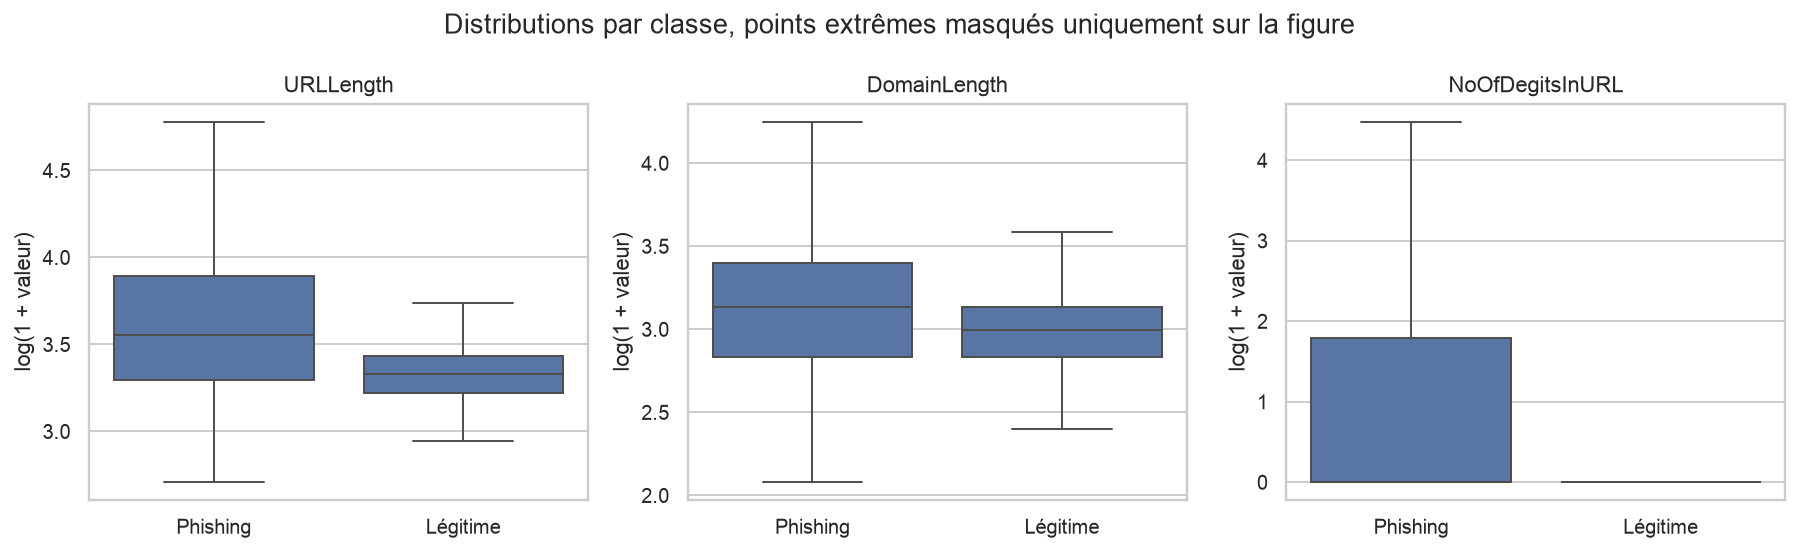

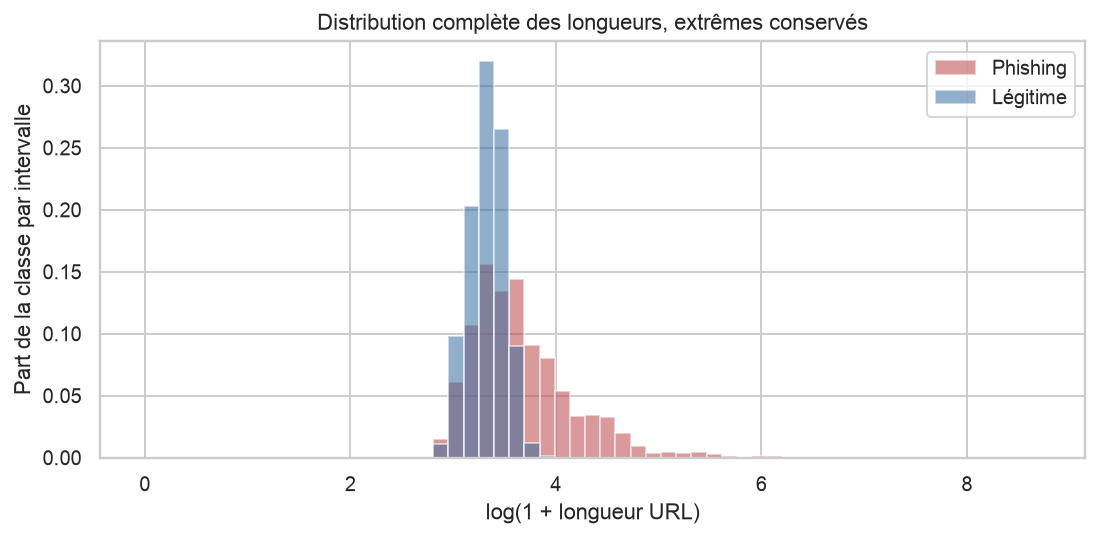

In [6]:
display(outputs["statistiques"])
display(Image(filename=str(FIG / "02_distributions.png")))
display(Image(filename=str(FIG / "08_longueurs_completes.png")))

## Comparaisons entre classes

| variable | Phishing | Legitime |
| --- | --- | --- |
| URLLength_calc | 34.000 | 27.000 |
| DomainLength_calc | 22.000 | 19.000 |
| NoOfLettersInURL_calc | 25.000 | 22.000 |
| NoOfDegitsInURL_calc | 0.000 | 0.000 |

| variable | Phishing | Légitime |
| --- | --- | --- |
| IsDomainIP_calc | 0.602 | 0.000 |
| IsHTTPS_calc | 48.735 | 100.000 |
| has_percent_encoding | 0.879 | 0.000 |


HTTPS est présent chez tous les légitimes, mais aussi chez 48.74 % des phishing. Il ne garantit donc pas la légitimité. Les IP et le percent-encoding ne concernent que 0.60 % et 0.88 % des phishing ; leur absence ne permet pas d'écarter le risque.

Aucune variable numérique n'est constante. Les caractéristiques suivantes ont une modalité représentant au moins 99 % des lignes : IsDomainIP_calc, has_percent_encoding, percent_encoded_count, percent_encoded_ratio. Un signal rare peut concerner une sous-population utile ; sa faible fréquence ne suffit pas à l'exclure.


,URLLength_calc_median,URLLength_calc_mean,URLLength_calc_min,URLLength_calc_max,DomainLength_calc_median,DomainLength_calc_mean,DomainLength_calc_min,DomainLength_calc_max,IsDomainIP_calc_median,IsDomainIP_calc_mean,IsDomainIP_calc_min,...,has_percent_encoding_mean,has_percent_encoding_min,has_percent_encoding_max,percent_encoded_count_median,percent_encoded_count_mean,percent_encoded_count_min,percent_encoded_count_max,percent_encoded_ratio_median,percent_encoded_ratio_mean,percent_encoded_ratio_min,percent_encoded_ratio_max
label,,,,,,,,,,,,,,,,,,,,,,,
0,34.0,46.238774,14,6097,22.0,24.461647,4,110,0.0,0.006023,0,...,0.008787,0,1,0.0,0.058527,0,149,0.0,0.000251,0.0,0.29484
1,27.0,27.228610,16,58,19.0,19.228610,8,50,0.0,0.000000,0,...,0.000000,0,0,0.0,0.000000,0,0,0.0,0.000000,0.0,0.00000


,variable,Phishing,Légitime
0,IsDomainIP_calc,0.602308,0.0
1,IsHTTPS_calc,48.735450,100.0
2,has_percent_encoding,0.878696,0.0


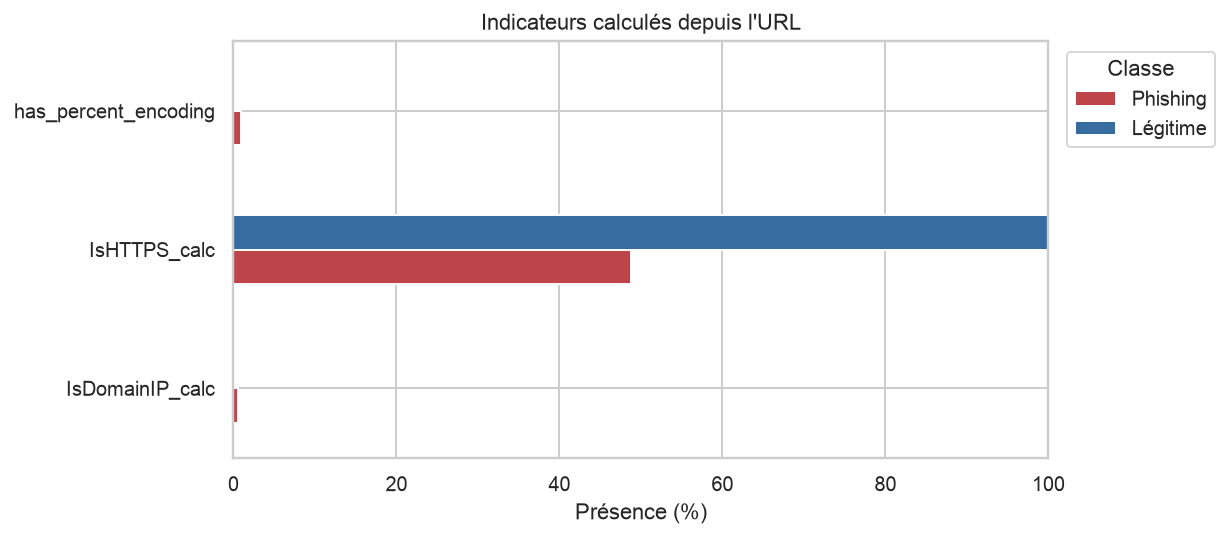

In [7]:
display(outputs["statistiques_par_classe"])
display(pd.read_csv(BASE / "reports/tables/eda_indicateurs_par_classe.csv"))
display(Image(filename=str(FIG / "03_indicateurs.png")))

## TLD : effectifs et proportions

Le calcul normalisé fournit 570 catégories de TLD, y compris la modalité vide. Parmi les catégories affichées, 300 comptent moins de dix observations. Les différences avec les 695 valeurs du champ TLD original ne sont pas un effet du nettoyage : elles résultent de l'extraction depuis l'hôte et de la convention IP, notamment.

| TLD_calc | phishing | legitime | total | phishing_pct |
| --- | --- | --- | --- | --- |
| com | 43780 | 68785 | 112565 | 38.893 |
| org | 2269 | 16524 | 18793 | 12.074 |
| net | 3099 | 3998 | 7097 | 43.666 |
| app | 6368 | 140 | 6508 | 97.849 |
| uk | 322 | 6073 | 6395 | 5.035 |
| co | 4964 | 458 | 5422 | 91.553 |
| io | 3769 | 432 | 4201 | 89.717 |
| de | 686 | 3310 | 3996 | 17.167 |
| ru | 2983 | 892 | 3875 | 76.981 |
| au | 373 | 2606 | 2979 | 12.521 |
| dev | 2312 | 33 | 2345 | 98.593 |
| top | 2327 | 2 | 2329 | 99.914 |



Les deux figures répondent à des questions distinctes : combien de lignes et quelle composition interne par classe ? Les proportions observées dans le CSV ne sont pas des probabilités de phishing dans la population réelle. Les petites catégories et les domaines répétés rendent certaines estimations fragiles. TLD_calc n'est pas traité comme un nombre dans la matrice de corrélation.


,phishing,legitime,total,phishing_pct
TLD_calc,,,,
com,43780,68785,112565,38.893084
org,2269,16524,18793,12.073644
net,3099,3998,7097,43.666338
app,6368,140,6508,97.848801
uk,322,6073,6395,5.035184
co,4964,458,5422,91.552932
io,3769,432,4201,89.716734
de,686,3310,3996,17.167167
ru,2983,892,3875,76.980645


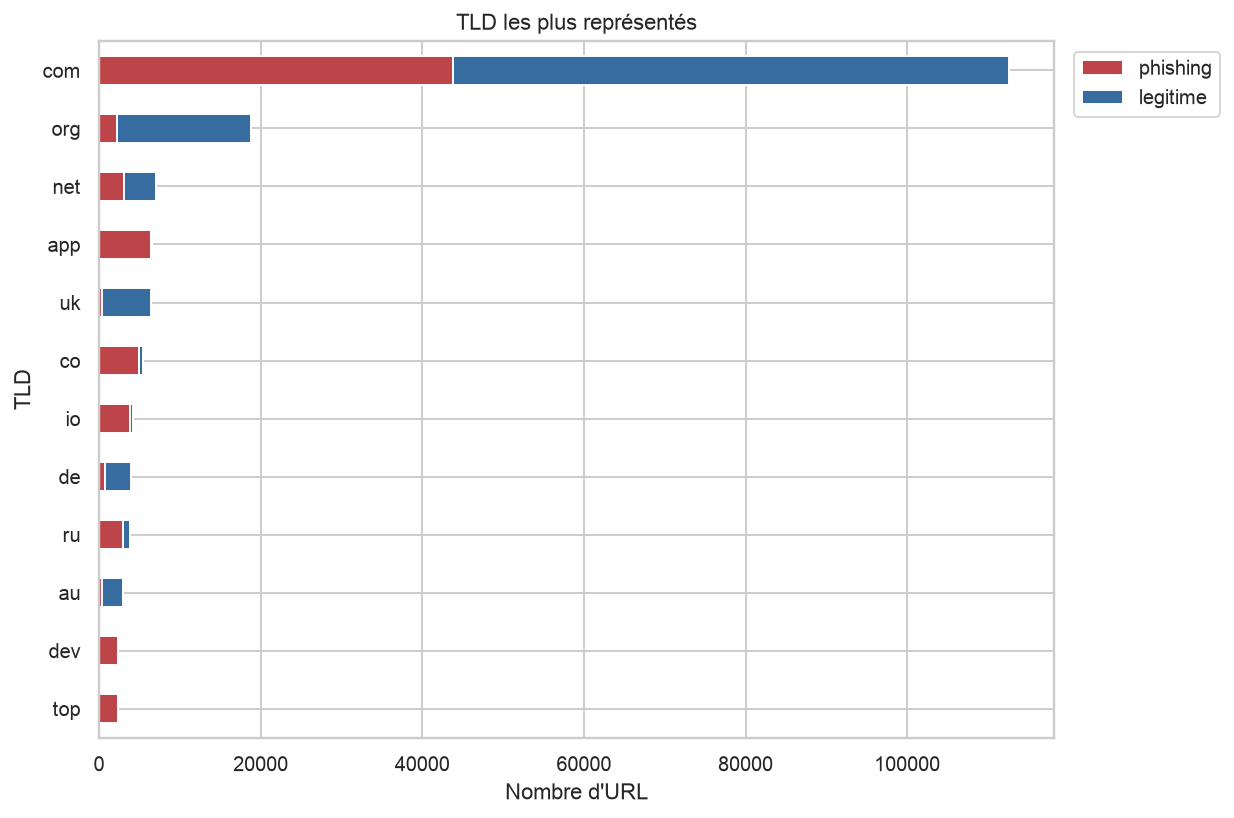

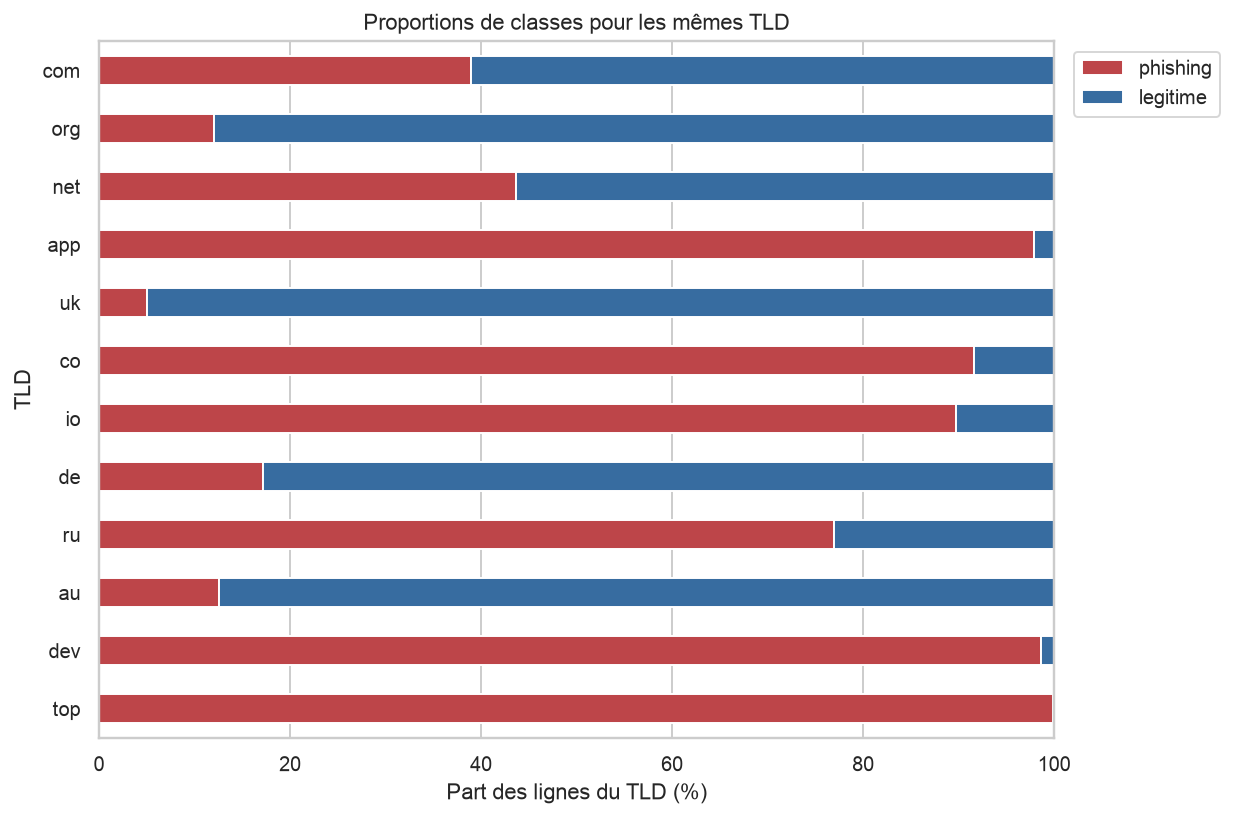

In [8]:
display(outputs["tld"].head(20))
display(Image(filename=str(FIG / "06_tld_effectifs.png")))
display(Image(filename=str(FIG / "07_tld_proportions.png")))

## Corrélations et redondances

| variable | spearman | pearson |
| --- | --- | --- |
| IsHTTPS_calc | 0.613 | 0.613 |
| NoOfOtherSpecialCharsInURL_calc | -0.555 | -0.277 |
| NoOfDegitsInURL_calc | -0.542 | -0.178 |
| DegitRatioInURL_calc | -0.537 | -0.433 |
| URLLength_calc | -0.380 | -0.228 |
| LetterRatioInURL_calc | 0.292 | 0.351 |
| NoOfLettersInURL_calc | -0.270 | -0.213 |
| DomainLength_calc | -0.213 | -0.283 |
| NoOfQMarkInURL_calc | -0.189 | -0.176 |
| NoOfEqualsInURL_calc | -0.178 | -0.078 |
| NoOfAmpersandInURL_calc | -0.127 | -0.089 |
| SpacialCharRatioInURL_calc | 0.085 | 0.127 |
| has_percent_encoding | -0.071 | -0.071 |
| percent_encoded_count | -0.071 | -0.035 |
| percent_encoded_ratio | -0.071 | -0.052 |
| IsDomainIP_calc | -0.059 | -0.059 |
| TLDLength_calc | -0.049 | -0.064 |


Spearman mesure une association monotone sur les rangs ; Pearson mesure une association linéaire. Avec label = 1 pour légitime, un coefficient positif correspond à des valeurs plus élevées du côté légitime. Le plus fort coefficient absolu de Spearman est ici celui de IsHTTPS_calc (0.613). Il ne mesure ni la causalité ni l'importance d'un modèle.


| variable_1 | variable_2 | spearman |
| --- | --- | --- |
| percent_encoded_count | percent_encoded_ratio | 1.000 |
| has_percent_encoding | percent_encoded_count | 1.000 |
| has_percent_encoding | percent_encoded_ratio | 1.000 |
| NoOfDegitsInURL_calc | DegitRatioInURL_calc | 0.997 |
| URLLength_calc | NoOfLettersInURL_calc | 0.956 |
| NoOfEqualsInURL_calc | NoOfQMarkInURL_calc | 0.915 |

Les ratios partagent leurs compteurs et le même dénominateur. Les indicateurs de percent-encoding sont presque redondants dans ce fichier, et le nombre de chiffres est fortement associé à son ratio. Aucune variable n'est supprimée automatiquement sur la seule corrélation. La comparaison des trois modèles et les éventuelles sélections devront être réalisées dans un protocole séparé, sans utiliser le test pour choisir.


,spearman,pearson
variable,,
IsHTTPS_calc,0.612874,0.612874
NoOfOtherSpecialCharsInURL_calc,-0.554709,-0.277197
NoOfDegitsInURL_calc,-0.541618,-0.178384
DegitRatioInURL_calc,-0.537416,-0.433431
URLLength_calc,-0.380479,-0.228229
LetterRatioInURL_calc,0.291913,0.350569
NoOfLettersInURL_calc,-0.269840,-0.212524
DomainLength_calc,-0.213365,-0.283014
NoOfQMarkInURL_calc,-0.189012,-0.175813


,variable_1,variable_2,spearman
271,percent_encoded_count,percent_encoded_ratio,0.999999
253,has_percent_encoding,percent_encoded_count,0.999998
254,has_percent_encoding,percent_encoded_ratio,0.999998
127,NoOfDegitsInURL_calc,DegitRatioInURL_calc,0.996849
5,URLLength_calc,NoOfLettersInURL_calc,0.956332
163,NoOfEqualsInURL_calc,NoOfQMarkInURL_calc,0.914857


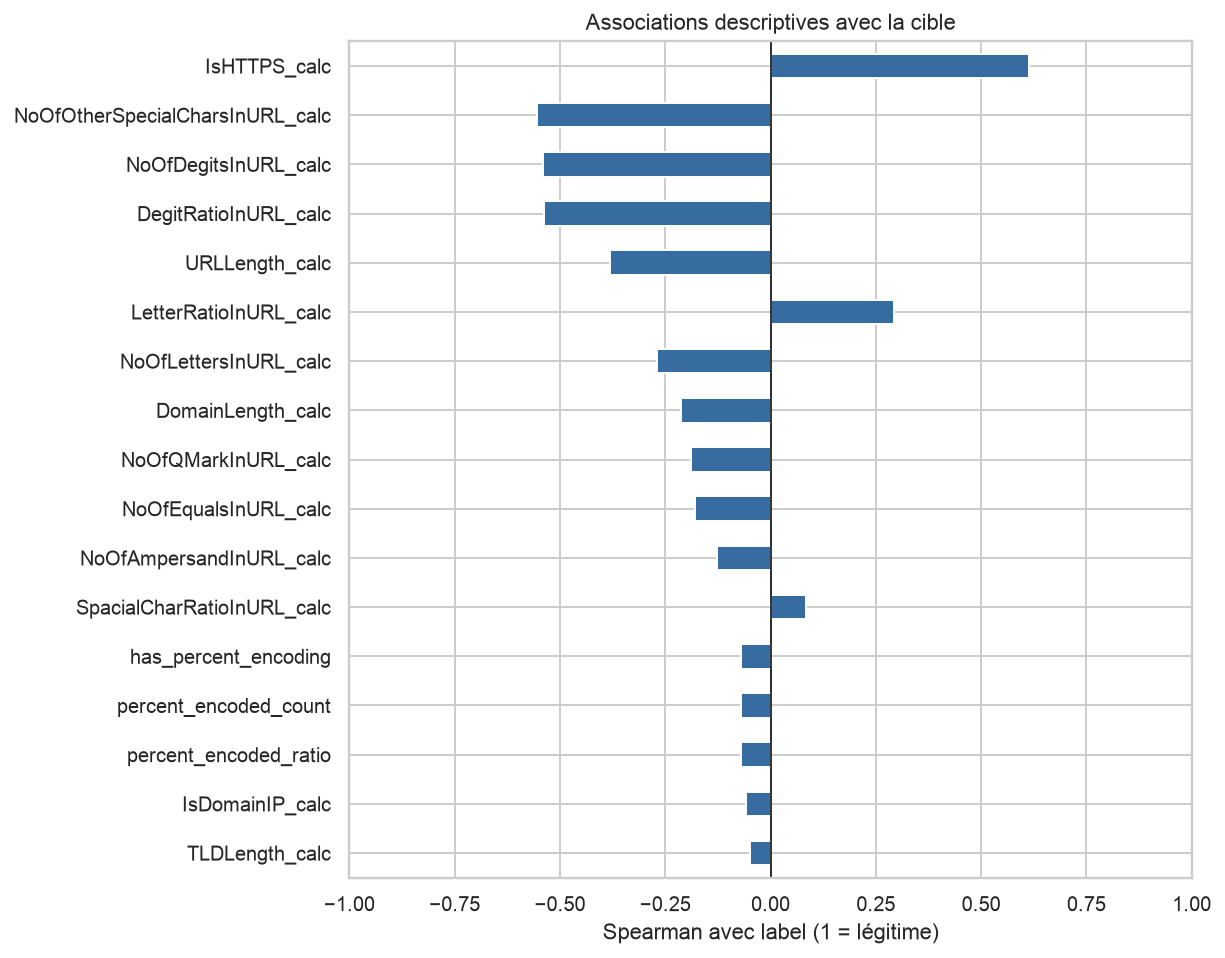

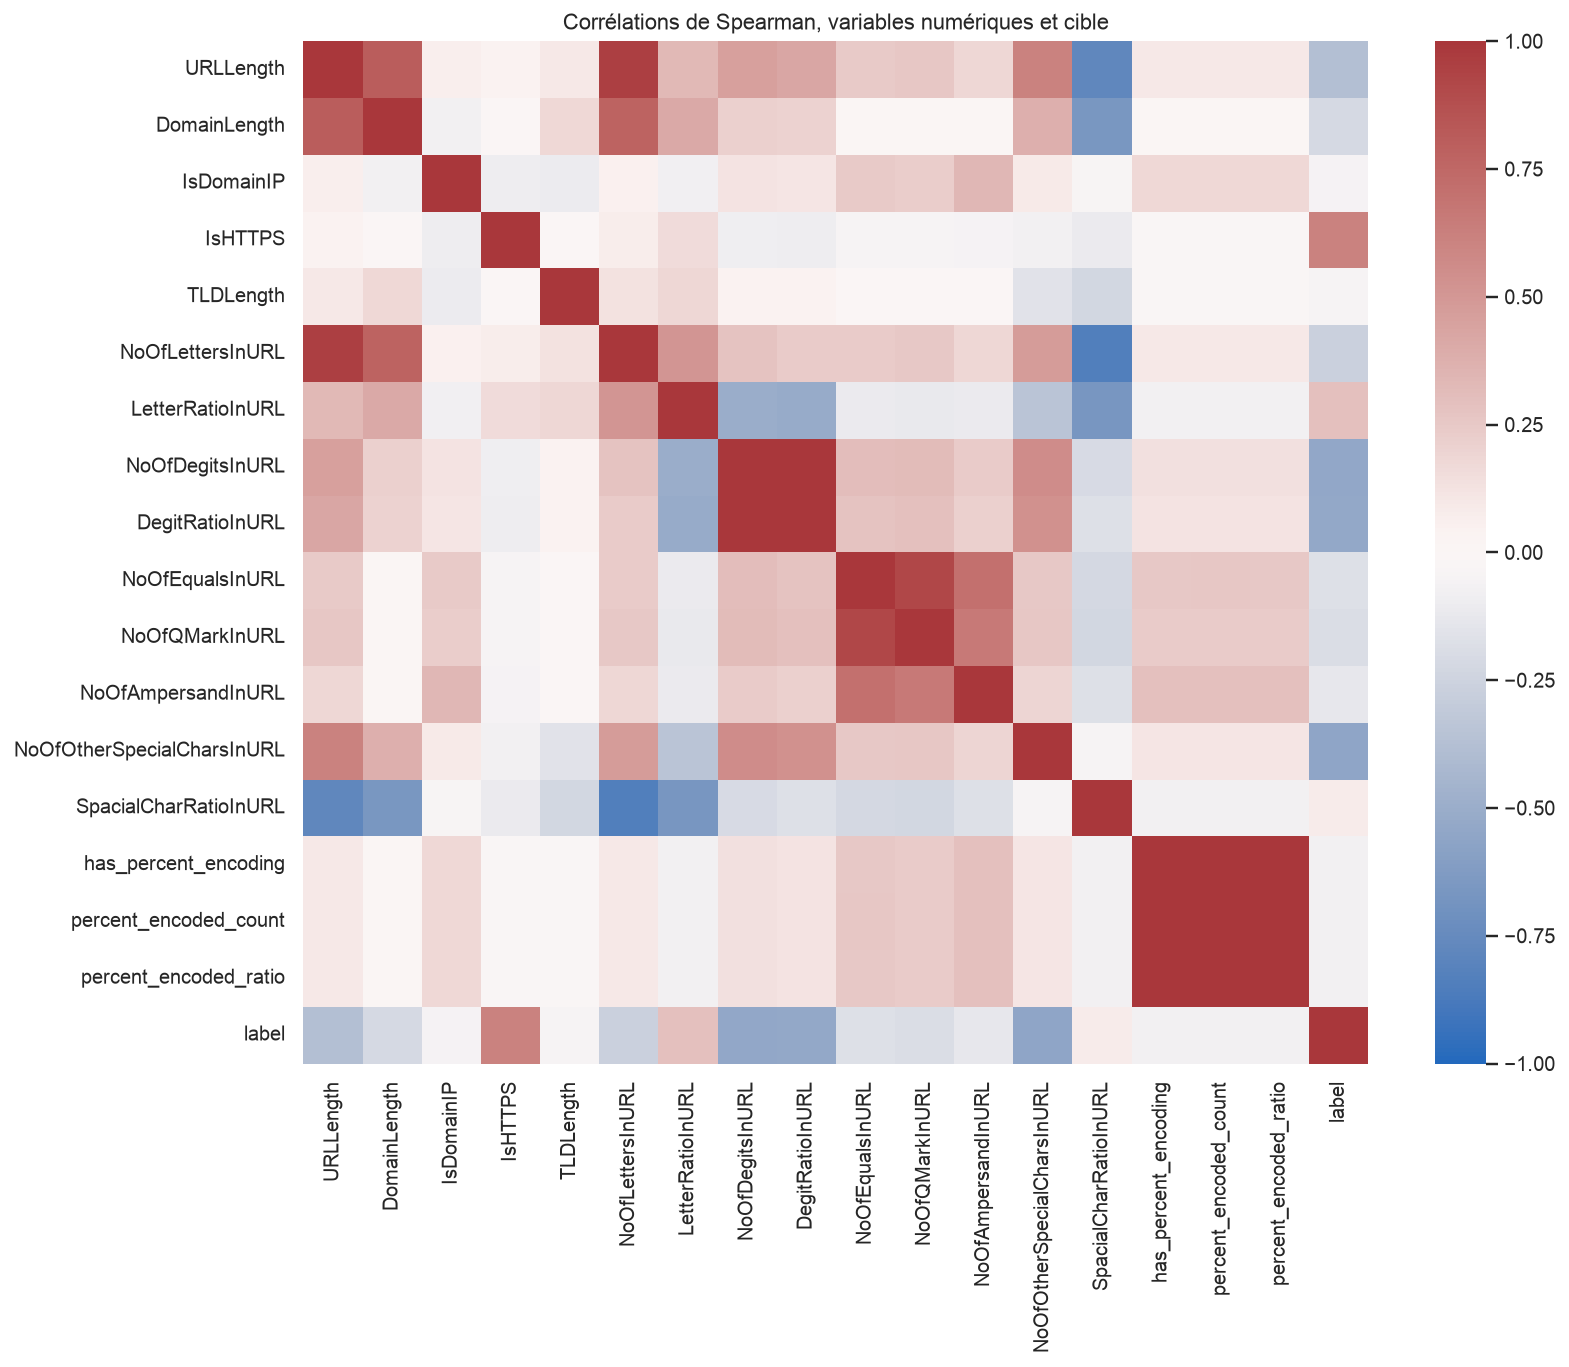

In [9]:
display(outputs["correlations_cible"])
display(outputs["redondances"])
display(Image(filename=str(FIG / "05_correlations_cible.png")))
display(Image(filename=str(FIG / "04_correlations.png")))

## Biais de structure et limites de généralisation

| label | effectif | chemin_non_racine | parametres | fragment |
| --- | --- | --- | --- | --- |
| 0 | 100945 | 27456 | 6079 | 832 |
| 1 | 134850 | 0 | 0 | 0 |

Aucune URL légitime de ce fichier ne possède de chemin non racine, de paramètres ou de fragment, alors que les phishing incluent ces formes. Un modèle peut donc apprendre une particularité de la collecte plutôt qu'une propriété universelle du phishing. Les longueurs et les caractères restent concernés même si l'on n'ajoute pas explicitement un indicateur de chemin.

La reconstruction améliore la reproductibilité des entrées ; elle ne corrige pas ce biais, les erreurs possibles des labels ni la représentativité du corpus. Un jeu externe contenant des URL légitimes profondes et des phishing variés serait nécessaire pour étudier la généralisation. Aucun site n'est visité pour vérifier son état actuel.


In [10]:
display(outputs["structure_url"])

,label,effectif,chemin_non_racine,parametres,fragment
0,0,100945,27456,6079,832
1,1,134850,0,0,0


## Transmissions au nettoyage et au découpage

Le nettoyage doit supprimer les copies d'une même URL de même label, conserver les URL différentes d'un même domaine et ne pas retirer les extrêmes valides automatiquement. Il doit garder une trace des exclusions, vérifier la conservation des labels et contrôler les invariants des caractéristiques. Les regroupements par domaine sont transmis au responsable du découpage ; aucune séparation train, validation ou test n'est créée ici.
